## Etape 1

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as ps

In [9]:
series = pd.read_csv('pjme-hourly.csv')

In [4]:
series.head()

,Datetime,PJME_MW
0,2002-12-31 01:00:00,26498.0
1,2002-12-31 02:00:00,25147.0
2,2002-12-31 03:00:00,24574.0
3,2002-12-31 04:00:00,24393.0
4,2002-12-31 05:00:00,24860.0


In [11]:
series.info()

<class 'pandas.DataFrame'>
RangeIndex: 145366 entries, 0 to 145365
Data columns (total 2 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   Datetime  145366 non-null  str    
 1   PJME_MW   145366 non-null  float64
dtypes: float64(1), str(1)
memory usage: 4.9 MB


In [12]:
series['Datetime']=pd.to_datetime(series['Datetime'])
series

,Datetime,PJME_MW
0,2002-12-31 01:00:00,26498.0
1,2002-12-31 02:00:00,25147.0
2,2002-12-31 03:00:00,24574.0
3,2002-12-31 04:00:00,24393.0
4,2002-12-31 05:00:00,24860.0
...,...,...
145361,2018-01-01 20:00:00,44284.0
145362,2018-01-01 21:00:00,43751.0
145363,2018-01-01 22:00:00,42402.0
145364,2018-01-01 23:00:00,40164.0


In [13]:
series.dtypes

Datetime    datetime64[us]
PJME_MW            float64
dtype: object

In [14]:
series.describe()

,Datetime,PJME_MW
count,145366,145366.000000
mean,2010-04-18 03:25:25.999202,32080.222831
min,2002-01-01 01:00:00,14544.000000
25%,2006-02-23 14:15:00,27573.000000
50%,2010-04-18 04:30:00,31421.000000
75%,2014-06-10 18:45:00,35650.000000
max,2018-08-03 00:00:00,62009.000000
std,NaN,6464.012166


In [15]:
series['PJME_MW'].describe()

count    145366.000000
mean      32080.222831
std        6464.012166
min       14544.000000
25%       27573.000000
50%       31421.000000
75%       35650.000000
max       62009.000000
Name: PJME_MW, dtype: float64

In [17]:
print(series["Datetime"].min(), series["Datetime"].max())
print(series["Datetime"].max() - series["Datetime"].min())

2002-01-01 01:00:00 2018-08-03 00:00:00
6057 days 23:00:00


In [18]:
print(series["Datetime"].is_monotonic_increasing)

False


In [19]:
print(series["Datetime"].sort_values().diff().value_counts().head())

Datetime
0 days 01:00:00    145331
0 days 02:00:00        30
0 days 00:00:00         4
Name: count, dtype: int64


In [ ]:
print(series.isna().sum())

Datetime    0
PJME_MW     0
dtype: int64


In [23]:
print(series["Datetime"].duplicated().sum())

4


In [30]:
full_range = pd.date_range(series["Datetime"].min(), series["Datetime"].max(), freq="h")
missing_ts = full_range.difference(series["Datetime"])
print(full_range)
print("les heurs manquants:", len(missing_ts))
print(missing_ts[:10])

DatetimeIndex(['2002-01-01 01:00:00', '2002-01-01 02:00:00',
               '2002-01-01 03:00:00', '2002-01-01 04:00:00',
               '2002-01-01 05:00:00', '2002-01-01 06:00:00',
               '2002-01-01 07:00:00', '2002-01-01 08:00:00',
               '2002-01-01 09:00:00', '2002-01-01 10:00:00',
               ...
               '2018-08-02 15:00:00', '2018-08-02 16:00:00',
               '2018-08-02 17:00:00', '2018-08-02 18:00:00',
               '2018-08-02 19:00:00', '2018-08-02 20:00:00',
               '2018-08-02 21:00:00', '2018-08-02 22:00:00',
               '2018-08-02 23:00:00', '2018-08-03 00:00:00'],
              dtype='datetime64[us]', length=145392, freq='h')
les heurs manquants: 30
DatetimeIndex(['2002-04-07 03:00:00', '2002-10-27 02:00:00',
               '2003-04-06 03:00:00', '2003-10-26 02:00:00',
               '2004-04-04 03:00:00', '2004-10-31 02:00:00',
               '2005-04-03 03:00:00', '2005-10-30 02:00:00',
               '2006-04-02 03:00:00', '

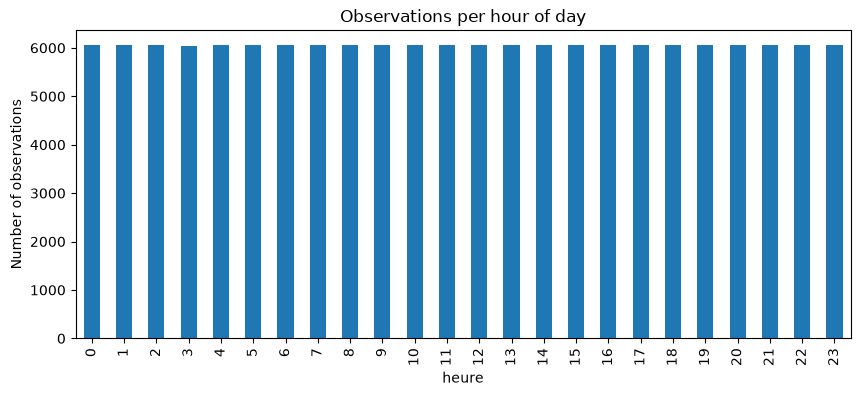

In [39]:
series["Datetime"].dt.hour.value_counts().sort_index().plot(
    kind="bar", figsize=(10, 4), title="Observations per hour of day")
plt.xlabel("heure")
plt.ylabel("Number of observations")
plt.show()

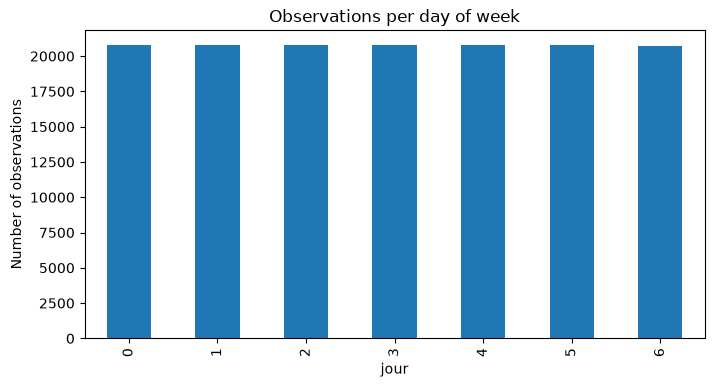

In [38]:
series["Datetime"].dt.dayofweek.value_counts().sort_index().plot(
    kind="bar", figsize=(8, 4), title="Observations per day of week")
plt.xlabel("jour")
plt.ylabel("Number of observations")
plt.show()

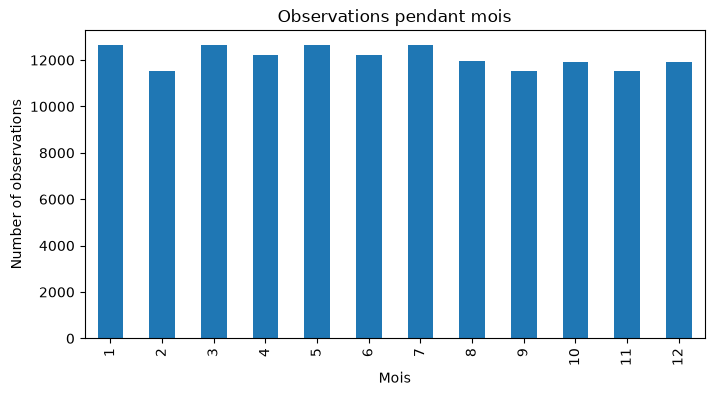

In [41]:
series["Datetime"].dt.month.value_counts().sort_index().plot(
    kind="bar", figsize=(8, 4), title="Observations pendant mois")
plt.xlabel("Mois")
plt.ylabel("Number of observations")
plt.show()

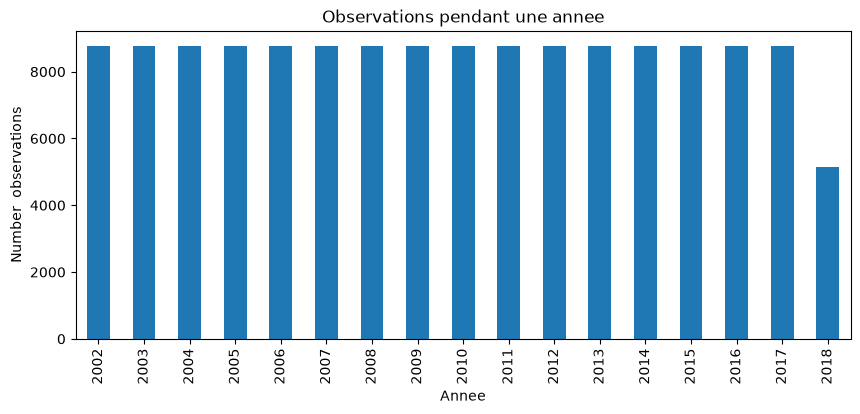

In [43]:
series["Datetime"].dt.year.value_counts().sort_index().plot(
    kind="bar", figsize=(10, 4), title="Observations pendant une annee")
plt.xlabel("Annee")
plt.ylabel("Number  observations")
plt.show()

## Etape 2

In [47]:
print(series.duplicated().sum())
print(series.isna().sum())

0
Datetime    0
PJME_MW     0
dtype: int64


In [49]:
full_range = pd.date_range(series["Datetime"].min(), series["Datetime"].max(), freq="h")
missing_ts = full_range.difference(series["Datetime"])
print(full_range)
print("les heurs manquants:", len(missing_ts))
print(missing_ts)

DatetimeIndex(['2002-01-01 01:00:00', '2002-01-01 02:00:00',
               '2002-01-01 03:00:00', '2002-01-01 04:00:00',
               '2002-01-01 05:00:00', '2002-01-01 06:00:00',
               '2002-01-01 07:00:00', '2002-01-01 08:00:00',
               '2002-01-01 09:00:00', '2002-01-01 10:00:00',
               ...
               '2018-08-02 15:00:00', '2018-08-02 16:00:00',
               '2018-08-02 17:00:00', '2018-08-02 18:00:00',
               '2018-08-02 19:00:00', '2018-08-02 20:00:00',
               '2018-08-02 21:00:00', '2018-08-02 22:00:00',
               '2018-08-02 23:00:00', '2018-08-03 00:00:00'],
              dtype='datetime64[us]', length=145392, freq='h')
les heurs manquants: 30
DatetimeIndex(['2002-04-07 03:00:00', '2002-10-27 02:00:00',
               '2003-04-06 03:00:00', '2003-10-26 02:00:00',
               '2004-04-04 03:00:00', '2004-10-31 02:00:00',
               '2005-04-03 03:00:00', '2005-10-30 02:00:00',
               '2006-04-02 03:00:00', '

##

In [52]:
s = series.set_index("Datetime")["PJME_MW"]

#### verifier les valuers negatifs

In [54]:
print(s.describe())
print("Valeurs nulles ou negatives :", (s <= 0).sum())

count    145366.000000
mean      32080.222831
std        6464.012166
min       14544.000000
25%       27573.000000
50%       31421.000000
75%       35650.000000
max       62009.000000
Name: PJME_MW, dtype: float64
Valeurs nulles ou negatives : 0


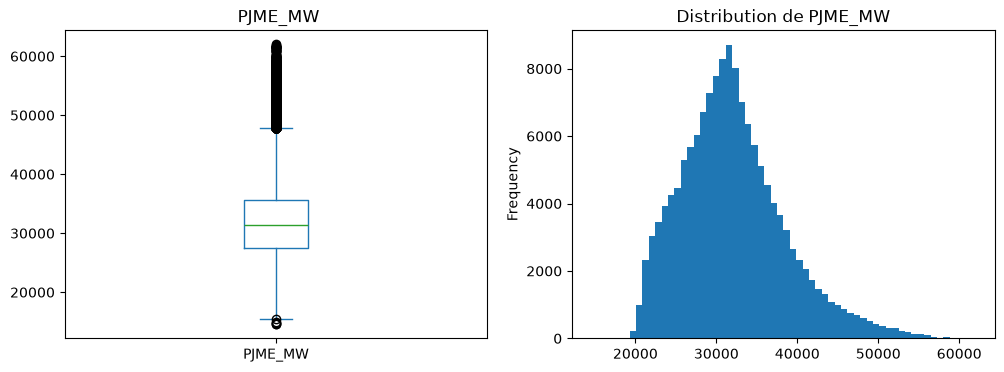

In [56]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
s.plot(kind="box", ax=ax[0], title=" PJME_MW")
s.plot(kind="hist", bins=60, ax=ax[1], title="Distribution de PJME_MW")
plt.show()

In [57]:
z = (s - s.mean()) / s.std()
anomalies_z = s[z.abs() > 3]
print("Anomalies :", len(anomalies_z))

Anomalies : 1318


### Anomalies contextules

In [58]:
groupes = [s.index.month, s.index.hour]
moyenne = s.groupby(groupes).transform("mean")
ecart_type = s.groupby(groupes).transform("std")

z_ctx = (s - moyenne) / ecart_type
anomalies = s[z_ctx.abs() > 3.5]

print("Anomalies contextuelles :", len(anomalies))
print("Les plus basses :")
print(anomalies.sort_values().head(10))
print("Les plus hautes :")
print(anomalies.sort_values().tail(10))

Anomalies contextuelles : 228
Les plus basses :
Datetime
2012-10-30 04:00:00    14544.0
2012-10-30 03:00:00    14586.0
2012-10-30 05:00:00    14821.0
2012-10-30 02:00:00    14955.0
2012-10-30 01:00:00    15390.0
2012-10-30 06:00:00    15526.0
2012-10-30 00:00:00    15919.0
2012-10-29 23:00:00    17422.0
2012-10-30 09:00:00    18675.0
2012-10-29 22:00:00    19085.0
Name: PJME_MW, dtype: float64
Les plus hautes :
Datetime
2011-05-31 15:00:00    51593.0
2012-05-29 16:00:00    51665.0
2012-05-29 17:00:00    51936.0
2011-05-31 18:00:00    52451.0
2011-05-31 16:00:00    52529.0
2006-08-01 23:00:00    52561.0
2006-08-02 23:00:00    52774.0
2011-05-31 17:00:00    53057.0
2006-08-01 22:00:00    56774.0
2006-08-02 22:00:00    56822.0
Name: PJME_MW, dtype: float64


In [59]:
diff = s.diff().abs()
seuil = diff.quantile(0.999)
sauts = diff[diff > seuil]

print("Plus gros sauts horaires :")
print(sauts.sort_values(ascending=False).head(10))

Plus gros sauts horaires :
Datetime
2012-06-19 01:00:00    15998.0
2002-07-28 01:00:00    14285.0
2014-01-06 01:00:00    13689.0
2014-06-16 01:00:00    13493.0
2011-06-07 01:00:00    13416.0
2014-07-06 01:00:00    13137.0
2005-07-25 01:00:00    13026.0
2002-07-27 01:00:00    12984.0
2007-06-25 01:00:00    12417.0
2012-06-20 01:00:00    12398.0
Name: PJME_MW, dtype: float64


In [51]:
df = series.sort_values("Datetime").drop_duplicates("Datetime")


s = df.set_index("Datetime")["PJME_MW"]


full_range = pd.date_range(s.index.min(), s.index.max(), freq="h")
s = s.reindex(full_range)
s.index.name = "Datetime"
print("NaN before interpolation:", s.isna().sum())


s_interp = s.interpolate(method="time", limit=3, limit_area="inside")
print("NaN after interpolation :", s_interp.isna().sum())


NaN before interpolation: 30
NaN after interpolation : 0
